   TV_Spend  Radio_Spend  Newspaper_Spend   Platform Target_Segment  Sales
0       122           37               35  Instagram          Youth  21.19
1       290           43                5    YouTube         Senior  30.95
2       126           11               58   Facebook          Youth  19.19
3        91           41                7   Facebook         Senior  16.62
4       208           32               20  Instagram         Senior  26.16
5        40           31               61   Facebook          Youth  18.24
6       122           34               79  Instagram         Senior  21.48
7       141           31               16    YouTube         Adults  21.35
8       234           31               78    YouTube         Senior  26.81
9       107           58               20     Google         Adults  27.14
Shape: (300, 6)


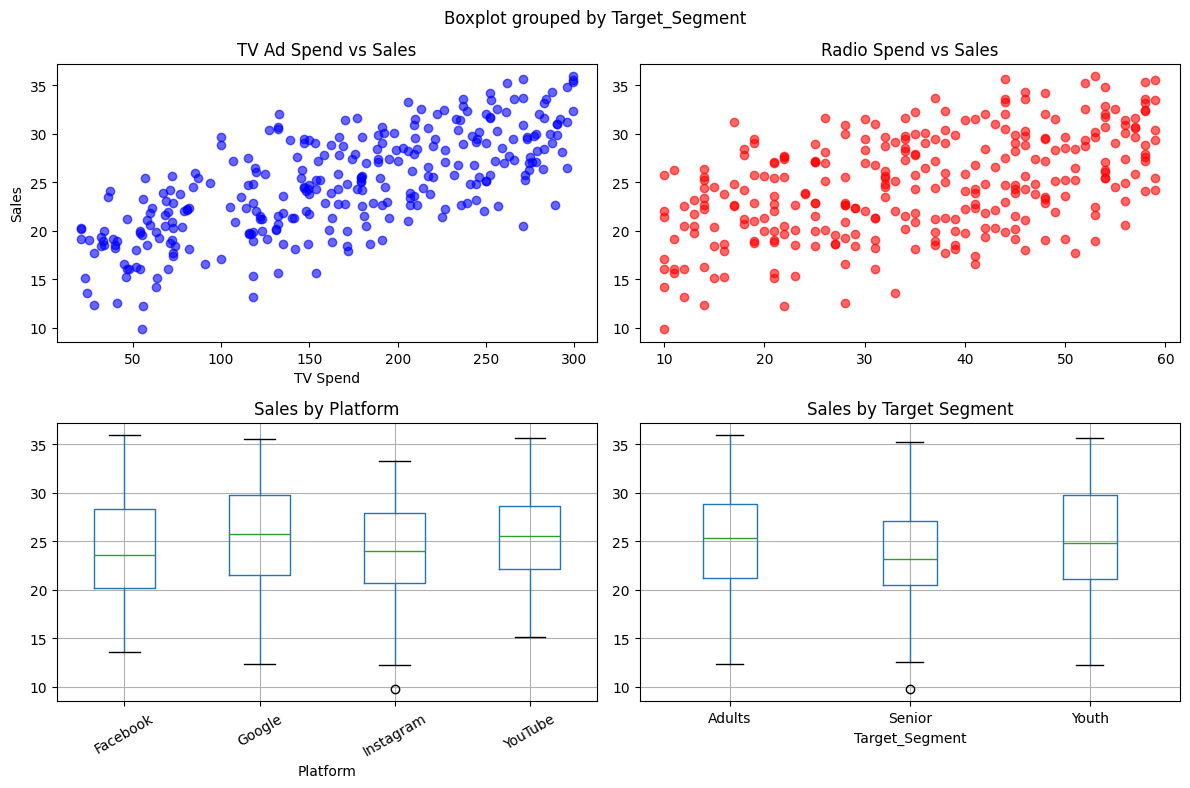

Linear Regression R2: 0.8028
Random Forest R2: 0.7789
MAE: 2.1142


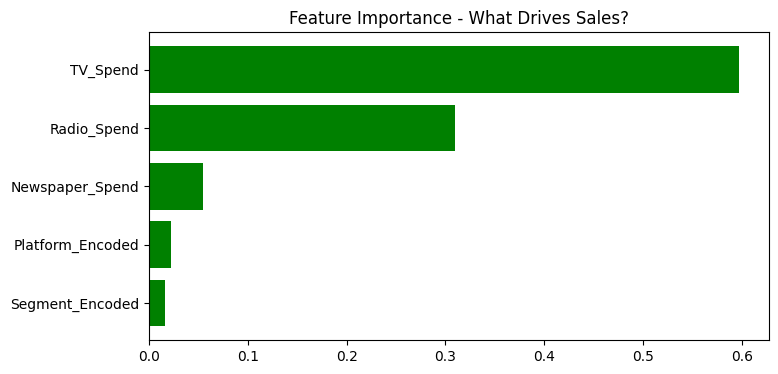

            Feature  Importance
0          TV_Spend    0.597647
1       Radio_Spend    0.309868
2   Newspaper_Spend    0.054443
3  Platform_Encoded    0.021978
4   Segment_Encoded    0.016063


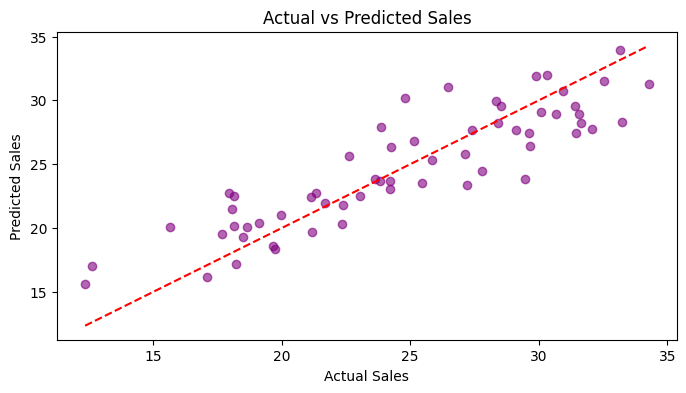


Predicted Sales for TV=200, YouTube, Youth Target: 27.26 units

Insights: TV & Radio have highest impact on sales, YouTube best platform, Youth best segment


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Create Sales Dataset (Advertising Spend vs Sales)
np.random.seed(42)
n = 300
tv = np.random.randint(20, 300, n)
radio = np.random.randint(10, 60, n)
newspaper = np.random.randint(5, 80, n)
platform = np.random.choice(['Facebook', 'Instagram', 'Google', 'YouTube'], n)
segment = np.random.choice(['Youth', 'Adults', 'Senior'], n)

# Sales logic: TV & Radio impact high
platform_val = {'Facebook':2, 'Instagram':3, 'Google':4, 'YouTube':5}
segment_val = {'Youth':3, 'Adults':2, 'Senior':1}
sales = (tv*0.05 + radio*0.2 + newspaper*0.02 +
         np.array([platform_val[p] for p in platform])*0.5 +
         np.array([segment_val[s] for s in segment])*0.8 +
         np.random.normal(0,2,n) + 5)

df = pd.DataFrame({
    'TV_Spend': tv,
    'Radio_Spend': radio,
    'Newspaper_Spend': newspaper,
    'Platform': platform,
    'Target_Segment': segment,
    'Sales': np.round(sales,2)
})
print(df.head(10))
print("Shape:", df.shape)

# Visualization 1
plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
plt.scatter(df['TV_Spend'], df['Sales'], alpha=0.6, color='blue')
plt.title('TV Ad Spend vs Sales')
plt.xlabel('TV Spend')
plt.ylabel('Sales')

plt.subplot(2,2,2)
plt.scatter(df['Radio_Spend'], df['Sales'], alpha=0.6, color='red')
plt.title('Radio Spend vs Sales')

plt.subplot(2,2,3)
df.boxplot(column='Sales', by='Platform', ax=plt.gca())
plt.title('Sales by Platform')
plt.xticks(rotation=30)

plt.subplot(2,2,4)
df.boxplot(column='Sales', by='Target_Segment', ax=plt.gca())
plt.title('Sales by Target Segment')
plt.tight_layout()
plt.show()

# Preprocessing - Encode categorical
from sklearn.preprocessing import LabelEncoder
le1 = LabelEncoder()
le2 = LabelEncoder()
df['Platform_Encoded'] = le1.fit_transform(df['Platform'])
df['Segment_Encoded'] = le2.fit_transform(df['Target_Segment'])

X = df[['TV_Spend', 'Radio_Spend', 'Newspaper_Spend', 'Platform_Encoded', 'Segment_Encoded']]
y = df['Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
print(f"Linear Regression R2: {r2_score(y_test, y_pred_lr):.4f}")

# Model 2: Random Forest (Best for business)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(f"Random Forest R2: {r2_score(y_test, y_pred_rf):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_rf):.4f}")

# Feature Importance - Business Insights!
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8,4))
plt.barh(importance['Feature'], importance['Importance'], color='green')
plt.title('Feature Importance - What Drives Sales?')
plt.gca().invert_yaxis()
plt.show()
print(importance)

# Actual vs Predicted
plt.figure(figsize=(8,4))
plt.scatter(y_test, y_pred_rf, alpha=0.6, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.show()

# Business Prediction Example
new_ad = pd.DataFrame([[200, 40, 30, 3, 0]], columns=X.columns) # High TV, YouTube, Youth
pred_sales = rf.predict(new_ad)
print(f"\nPredicted Sales for TV=200, YouTube, Youth Target: {pred_sales[0]:.2f} units")
print("\nInsights: TV & Radio have highest impact on sales, YouTube best platform, Youth best segment")